# Entregable 3. Benchmark de modelos con validación anidada, optimización y modelo original

En este entregable llevamos el modelo base del Entregable 2 a un benchmark completo. Comparamos siete modelos, cuatro técnicas de balanceo y cuatro métodos de optimización de hiperparámetros con validación cruzada anidada, y los evaluamos con calibración, interpretabilidad, robustez y una jerarquía de pruebas estadísticas. También sumamos un modelo original que salió de una búsqueda de literatura, el Explainable Boosting Machine (EBM).

Todo el código está en `src/benchmark.py` y en `scripts/`, y los resultados crudos de cada una de las tareas están en `resultados/tareas/`. Este notebook solo lee esos resultados y los interpreta.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG = RAIZ / "resultados", RAIZ / "resultados" / "figuras"
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
maestra = pd.read_csv(RES / "tabla_maestra.csv")
fold = pd.read_csv(RES / "resultados_por_fold.csv")
print(f"{len(maestra)} combinaciones en la tabla maestra, {len(fold)} tareas de validación externa")

108 combinaciones en la tabla maestra, 545 tareas de validación externa


## 1. Qué se pidió y qué se pudo hacer

La guía pide 7 modelos, 4 técnicas de balanceo y 4 optimizadores, es decir 7 × 4 × 4 = 112 combinaciones de clasificación, y 28 de regresión (7 × 4, porque el balanceo no aplica en regresión).

| Componente | Opciones |
|---|---|
| Modelos | KNN, Naive Bayes, Regresión logística (L1 y L2), Árbol de decisión, Random Forest, XGBoost, SVM lineal |
| Balanceo | Sin balanceo, SMOTE, ADASYN, class_weight balanced |
| Optimizadores | Grid Search, Random Search, Bayesiana (Optuna con TPE), Genética (DEAP) |

Dos decisiones que conviene dejar claras desde ya.

**La rama de regresión no aplica.** Nuestro desenlace es binario (dificultad cognitiva subjetiva sí o no). Los 28 modelos de regresión están pensados para un desenlace continuo, minimizan el error cuadrático y se evalúan con RMSE, MAE o R². En un desenlace 0 y 1 darían predicciones fuera del intervalo de 0 a 1, la varianza depende de la predicción (p por 1 menos p) y las métricas de regresión no dicen nada sobre discriminación ni calibración. Además no se podrían comparar con las 112 de clasificación bajo una métrica común, y eso rompería el ranking de Friedman. El modelo de regresión que corresponde a un desenlace binario es la logística, que ya está dentro de las 112, con y sin penalización.

**KNN no admite class_weight.** KNN no tiene pesos de clase ni pesos por muestra, así que esas 4 combinaciones (KNN con class_weight por cada optimizador) no se pueden correr sin inventar un método distinto. Quedan reportadas como no aplicables. El total efectivo es de 108 combinaciones, 5 folds externos cada una, es decir 540 tareas de validación externa, todas completadas sin errores.

## 2. Búsqueda de literatura y modelo original

Para el modelo original seguimos el método de las dos búsquedas con Scopus AI. En la primera buscamos qué modelos de machine learning se han usado para predecir dificultad cognitiva subjetiva con datos de encuestas poblacionales y factores de riesgo modificables. En la segunda buscamos modelos mejorados para datos tabulares, mayormente categóricos, de unos 15 predictores y unos 50 mil adultos. Después cruzamos los dos listados para ver qué modelo mejorado no aparecía aplicado a nuestro problema. Los dos archivos exportados traen 111 y 72 registros, con 8 títulos en común.

In [2]:
cruce = pd.DataFrame([
 ("Regresión logística y modelos estadísticos clásicos", "Muy usados con BRFSS, NHIS y HRS", "Ya está en nuestro benchmark"),
 ("Árboles, bosques y boosting (RF, XGBoost, LightGBM)", "Frecuentes en deterioro cognitivo en general, ninguno cruza SCD con encuesta poblacional en lo que revisamos", "Ya está en nuestro benchmark (RF, XGBoost)"),
 ("Redes con atención y costo sensible (Akter 2025)", "Único estudio con SCD, encuesta y desbalance (BRFSS 2021 a NHIS 2022)", "Antecedente más cercano, lo citamos"),
 ("Explainable Boosting Machine (EBM)", "Aparece en cognición y demencia, pero no con SCD en encuesta poblacional", "Candidato elegido como modelo original"),
 ("Neural Additive Models, RGALF", "Una referencia cada uno, sin SCD", "Descartados por costo y poca implementación disponible"),
 ("TabNet y transformers tabulares", "Cuatro registros que los mencionan, sin SCD", "Descartados por costo y porque rara vez superan a los árboles en datos tabulares"),
 ("Ensambles, stacking y voting", "Frecuentes (14 de los 72 registros de la segunda lista mencionan ensambles), sin SCD con encuesta", "Descartado por ser una combinación de modelos que ya probamos"),
], columns=["Familia de modelos", "Hallazgo en las listas", "Decisión"])
display(cruce.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

Familia de modelos,Hallazgo en las listas,Decisión
Regresión logística y modelos estadísticos clásicos,"Muy usados con BRFSS, NHIS y HRS",Ya está en nuestro benchmark
"Árboles, bosques y boosting (RF, XGBoost, LightGBM)","Frecuentes en deterioro cognitivo en general, ninguno cruza SCD con encuesta poblacional en lo que revisamos","Ya está en nuestro benchmark (RF, XGBoost)"
Redes con atención y costo sensible (Akter 2025),"Único estudio con SCD, encuesta y desbalance (BRFSS 2021 a NHIS 2022)","Antecedente más cercano, lo citamos"
Explainable Boosting Machine (EBM),"Aparece en cognición y demencia, pero no con SCD en encuesta poblacional",Candidato elegido como modelo original
"Neural Additive Models, RGALF","Una referencia cada uno, sin SCD",Descartados por costo y poca implementación disponible
TabNet y transformers tabulares,"Cuatro registros que los mencionan, sin SCD",Descartados por costo y porque rara vez superan a los árboles en datos tabulares
"Ensambles, stacking y voting","Frecuentes (14 de los 72 registros de la segunda lista mencionan ensambles), sin SCD con encuesta",Descartado por ser una combinación de modelos que ya probamos


Elegimos el **EBM** porque cumple todo lo que necesitamos. Es un modelo aditivo generalizado entrenado con boosting (Lou y colaboradores, 2013), así que cada variable tiene su propia función de forma que se puede leer como una curva. Maneja categorías y faltantes de forma nativa, se entrena en un minuto con 45 mil filas y es compatible con scikit-learn, de modo que entra en el mismo nested CV sin cambiar nada de la lógica anti fuga.

Para comprobar que no estuviera ya hecho buscamos en PubMed (EBM con SCD, y EBM con demencia o deterioro cognitivo). Lo que encontramos fue EBM en envejecimiento cognitivo sano (Mahamadou y colaboradores, 2025), en conversión de deterioro cognitivo leve a Alzheimer con imágenes de ADNI (Cai y colaboradores, 2023) y en diagnóstico de Alzheimer combinado con redes convolucionales (Kang y colaboradores, 2026). No encontramos EBM aplicado a SCD con encuesta poblacional.

**Alcance de esa afirmación.** Decimos que no lo encontramos, no que no exista. Las listas de Scopus AI son parciales y traen ruido (por ejemplo artículos de muerte súbita cardíaca), y PubMed no cubre bien la literatura de computación. La dejamos como una brecha plausible que habría que confirmar con una búsqueda directa en Scopus.

## 3. Diseño experimental sin fuga de información

La unidad de trabajo es el conjunto de entrenamiento del Entregable 2 (44,903 adultos). **El conjunto de prueba reservado (11,226) no se tocó durante la comparación**, solo se usa al final para los modelos finalistas.

* **Lazo externo.** Validación cruzada estratificada de 5 folds sobre el entrenamiento. En cada fold externo se entrena con 4 quintos y se mide en el quinto restante. Todas las métricas de las tablas salen de estos folds externos.
* **Lazo interno.** Dentro del entrenamiento de cada fold externo corre la búsqueda de hiperparámetros con una validación cruzada de 3 folds y PR-AUC como criterio de selección. Nunca ve el fold externo de validación.
* **Todo dentro del Pipeline.** Imputación, agrupación de categorías raras, splines de edad, escalado, one-hot, SMOTE y ADASYN se ajustan únicamente con los datos de entrenamiento de cada partición. El mismo preprocesador del Entregable 2 se usa en las 108 combinaciones, con la misma lista de variables excluidas por fuga (frecuencia de la dificultad, discapacidad y demencia).
* **Mismo presupuesto para todos.** Cada búsqueda tiene unas 12 evaluaciones. Random y Bayesiana hacen 12 (11.99 en promedio, porque una configuración repetida no se vuelve a evaluar). Grid usa una rejilla gruesa de 5 a 12 puntos según el modelo (10.1 en promedio). La genética arranca con 4 individuos y hace 3 generaciones con elitismo y caché de configuraciones repetidas, por lo que terminó evaluando en promedio 6.9 configuraciones distintas.
* **Optimización computacional.** La búsqueda interna usa una submuestra estratificada de 8,000 filas del entrenamiento del fold, y el modelo ganador se reajusta con todo el fold. Es lo que permitió completar 540 tareas con 2 núcleos. Es una decisión que ahorra tiempo a costa de algo de precisión en la búsqueda, y la declaramos como limitación.

El balanceo con SMOTE y ADASYN se aplica sobre las variables ya transformadas (one-hot y splines), lo que genera valores intermedios en las variables binarias. Es una aproximación habitual, y no usamos SMOTE-NC porque con splines y escalado no queda una separación limpia entre variables continuas y categóricas.

## 4. Resultados del benchmark (tabla maestra)

Esta es la tabla maestra completa con las métricas de validación externa (media y desviación entre los 5 folds). La guardamos entera en `resultados/tabla_maestra.csv`. Acá mostramos las 15 primeras por PR-AUC.

In [3]:
cols = ["modelo","balanceo","optimizador","PR_AUC_media","PR_AUC_sd","ROC_AUC_media","Brier_media","ECE_media","Recall_05_media","evals","t_total_min"]
display(maestra[cols].head(15).style.hide(axis="index").format(precision=3))

modelo,balanceo,optimizador,PR_AUC_media,PR_AUC_sd,ROC_AUC_media,Brier_media,ECE_media,Recall_05_media,evals,t_total_min
SVM,sin_balanceo,Grid,0.520,0.011,0.793,0.131,0.022,0.285,5.000,0.216
SVM,sin_balanceo,Genetica,0.520,0.011,0.793,0.131,0.022,0.285,5.600,0.239
SVM,sin_balanceo,Random,0.520,0.011,0.793,0.131,0.021,0.285,12.000,0.458
SVM,sin_balanceo,Bayesiana,0.520,0.011,0.793,0.131,0.022,0.285,12.000,0.450
XGBoost,class_weight,Bayesiana,0.520,0.012,0.792,0.183,0.222,0.697,12.000,0.805
LogReg,sin_balanceo,Random,0.519,0.012,0.793,0.131,0.016,0.286,12.000,0.588
LogReg,sin_balanceo,Grid,0.519,0.012,0.793,0.131,0.016,0.287,12.000,0.487
LogReg,sin_balanceo,Bayesiana,0.519,0.012,0.793,0.131,0.016,0.287,12.000,0.558
LogReg,sin_balanceo,Genetica,0.519,0.012,0.793,0.131,0.016,0.287,6.600,0.274
XGBoost,sin_balanceo,Bayesiana,0.519,0.011,0.792,0.131,0.019,0.257,12.000,0.756


Lo primero que se nota es que el techo es bajo y parejo. La mejor combinación llega a una PR-AUC de 0.520 y las primeras diez están todas entre 0.519 y 0.520, con una desviación entre folds de 0.011. Las diferencias entre ellas son más chicas que el ruido del propio fold, así que no se pueden ordenar con seguridad. Esto es coherente con lo que ya veíamos en el Entregable 2, donde la logística y la SVM lineal daban casi lo mismo y la curva de aprendizaje se aplanaba, lo que apunta a que el problema está limitado por la información de las 14 predictoras más que por la complejidad del modelo.

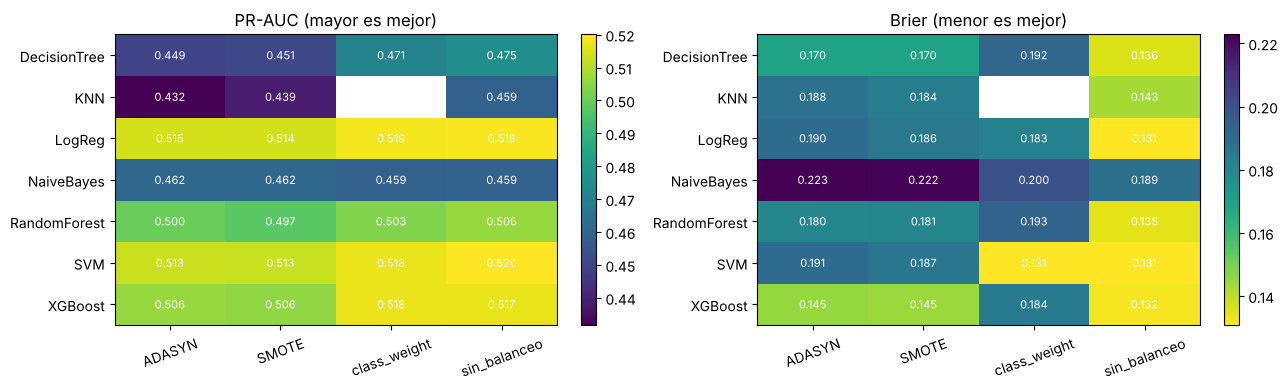

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, met, titulo in zip(ax, ["PR_AUC_media", "Brier_media"], ["PR-AUC (mayor es mejor)", "Brier (menor es mejor)"]):
    t = maestra.pivot_table(index="modelo", columns="balanceo", values=met)
    im = a.imshow(t.values, cmap="viridis" if met.startswith("PR") else "viridis_r", aspect="auto")
    a.set_xticks(range(t.shape[1])); a.set_xticklabels(t.columns, rotation=20); a.set_yticks(range(t.shape[0])); a.set_yticklabels(t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]; a.text(j, i, "n/a" if np.isnan(v) else f"{v:.3f}", ha="center", va="center", color="white", fontsize=8)
    a.set_title(titulo); plt.colorbar(im, ax=a, fraction=0.04)
plt.tight_layout(); plt.show()

En el mapa de calor se ve que los modelos lineales (logística y SVM) y XGBoost forman el grupo de arriba, Random Forest queda un escalón más abajo, y el árbol de decisión, Naive Bayes y KNN quedan claramente por debajo. Una explicación probable para KNN es que trabaja con 35 columnas transformadas, en las que las distancias son poco informativas. El árbol aislado es inestable, y Naive Bayes supone independencia entre predictoras que están claramente asociadas (por ejemplo depresión y frecuencia de síntomas depresivos). Son explicaciones razonables que no probamos con experimentos aparte.

En calibración la historia es otra, y es probablemente el hallazgo más útil del benchmark. **Todo balanceo que cambia la prevalencia efectiva empeora la calibración**, y eso se ve en el Brier de la derecha. Sin balanceo el Brier ronda 0.13 y con SMOTE, ADASYN o class_weight sube a 0.18 o más, porque el modelo ya no estima la probabilidad real de 20 % de prevalencia. A cambio sube el recall, de 0.25 sin balanceo a 0.6 con balanceo. La SVM con class_weight es la excepción en Brier (0.131) porque la SVM se calibra con un ajuste sigmoide posterior, que corrige justamente ese desfase.

In [5]:
res_bal = maestra.groupby("balanceo").agg(PR_AUC=("PR_AUC_media","mean"), Brier=("Brier_media","mean"), ECE=("ECE_media","mean"), Recall_umbral_05=("Recall_05_media","mean")).round(3)
display(res_bal)

,PR_AUC,Brier,ECE,Recall_umbral_05
balanceo,,,,
ADASYN,0.482,0.184,0.194,0.622
SMOTE,0.483,0.182,0.188,0.619
class_weight,0.498,0.181,0.182,0.606
sin_balanceo,0.494,0.142,0.048,0.252


## 5. Estadística jerárquica

La guía pide Friedman, luego Nemenyi con diagrama de diferencia crítica y luego DeLong con corrección de Holm, con tamaños de efecto. Lo aplicamos así y declaramos sus límites.

In [6]:
fr = json.load(open(RES / "friedman_por_factor.json"))
filas = []
for f_, v in fr.items():
    filas.append((f_, f"{v['chi2']:.2f}", f"{v['p']:.4f}", f"{v['CD']:.2f}", ", ".join(f"{k} {r}" for k, r in v["rangos"].items())))
display(pd.DataFrame(filas, columns=["Factor","Chi² de Friedman","p","Diferencia crítica (Nemenyi)","Rangos medios (1 es el mejor)"]).style.hide(axis="index").set_properties(**{"text-align":"left"}))

Factor,Chi² de Friedman,p,Diferencia crítica (Nemenyi),Rangos medios (1 es el mejor)
modelo,28.46,0.0001,4.03,"LogReg 1.2, SVM 2.2, XGBoost 2.6, RandomForest 4.0, DecisionTree 5.4, NaiveBayes 5.6, KNN 7.0"
balanceo,13.56,0.0036,2.10,"class_weight 1.0, sin_balanceo 2.0, SMOTE 3.4, ADASYN 3.6"
optimizador,8.76,0.0327,2.10,"Bayesiana 1.4, Grid 2.0, Random 3.0, Genetica 3.6"


**Friedman global.** Con las 108 combinaciones y los 5 folds externos como bloques, el test sale significativo (chi cuadrado de 507, p menor de 1e-50). Pero con 108 tratamientos y solo 5 bloques la diferencia crítica de Nemenyi es de unos 86 rangos, y como el máximo posible es 108, esa prueba no puede separar a ninguna pareja. Por eso el Nemenyi sirve en esta escala para los factores y no para las 108 combinaciones.

**Friedman por factor.** Para cada factor promediamos sobre los otros dos dentro de cada fold, de modo que los bloques siguen siendo los 5 folds. Esto debe leerse con cuidado, porque las combinaciones que se promedian no son independientes entre sí.

* **Modelos** (diferencia crítica de 4.03). La logística (rango 1.2) separa de KNN (7.0), Naive Bayes (5.6) y árbol (5.4). Entre logística, SVM y XGBoost no hay diferencia detectable.
* **Balanceo** (diferencia crítica de 2.10). class_weight (rango 1.0) queda por delante de SMOTE (3.4) y de ADASYN (3.6), y sin balanceo (2.0) no se distingue de class_weight. SMOTE y ADASYN no aportan nada sobre no balancear, y como vimos, además dañan la calibración.
* **Optimizador** (diferencia crítica de 2.10). La Bayesiana (1.4) queda por delante de la genética (3.6), con Grid (2.0) y Random (3.0) en el medio. Hay que tener presente que la genética evaluó solo 6.9 configuraciones distintas contra 12 de la Bayesiana y de Random, así que parte de esa diferencia es de presupuesto y no del algoritmo. La diferencia en PR-AUC interna es chica, de 0.482 contra 0.476.

In [7]:
dl = pd.read_csv(RES / "delong_vs_mejor.csv"); ef = pd.read_csv(RES / "cliffs_delta.csv")
d = dl.merge(ef.rename(columns={"cliffs_delta_mejor_vs":"delta_de_Cliff"}), on="combo", how="left")
display(d.style.hide(axis="index").format({"dif_AUC_vs_mejor":"{:.4f}","p":"{:.4f}","p_Holm":"{:.4f}","delta_de_Cliff":"{:.2f}"}))

combo,dif_AUC_vs_mejor,p,p_Holm,delta_de_Cliff
SVM|sin_balanceo|Genetica,0.0000,0.5254,1.0000,0.04
SVM|sin_balanceo|Random,0.0000,0.2693,1.0000,0.20
SVM|sin_balanceo|Bayesiana,0.0000,0.1551,1.0000,0.04
XGBoost|class_weight|Bayesiana,0.0016,0.0016,0.0254,0.04
LogReg|sin_balanceo|Random,0.0001,0.5987,1.0000,0.12
LogReg|sin_balanceo|Grid,0.0001,0.6170,1.0000,0.12
LogReg|sin_balanceo|Bayesiana,0.0002,0.5738,1.0000,0.12
LogReg|sin_balanceo|Genetica,0.0001,0.5966,1.0000,0.12
XGBoost|sin_balanceo|Bayesiana,0.0027,0.0000,0.0000,0.04
LogReg|class_weight|Bayesiana,-0.0000,0.9457,1.0000,0.12


**DeLong con Holm.** Comparamos la mejor combinación por PR-AUC (SVM sin balanceo con Grid) contra las 19 siguientes, usando las predicciones fuera de fold de todo el entrenamiento (AUC ROC). Las diferencias de AUC son del orden de milésimas y casi ninguna es significativa tras Holm. Las únicas que quedan significativas son las de XGBoost, cuyo AUC es unas 0.002 a 0.003 menor, una diferencia tan pequeña que no tiene relevancia práctica. El delta de Cliff sobre la PR-AUC por fold es de 0.04 a 0.20 en esas comparaciones, es decir efectos despreciables a pequeños. Con 5 folds el delta de Cliff solo puede tomar valores muy gruesos, así que lo usamos como apoyo y no como evidencia fuerte.

La conclusión estadística, que conviene decir con todas las letras, es que **no hay un ganador claro entre los modelos lineales, la SVM y XGBoost**, y que los factores que sí mueven los resultados son el tipo de modelo (los débiles quedan abajo) y la calibración que destruye el balanceo.

## 6. Optimización computacional y análisis de complejidad

optimizador,evaluaciones,PR-AUC interno,evaluaciones hasta llegar a 0.002 del óptimo,tiempo de búsqueda (s),tiempo por evaluación (s)
Bayesiana,11.993,0.482,4.415,10.972,0.915
Genetica,6.911,0.476,2.889,6.183,0.827
Grid,10.074,0.480,5.000,10.108,0.910
Random,11.978,0.479,4.252,10.950,0.915


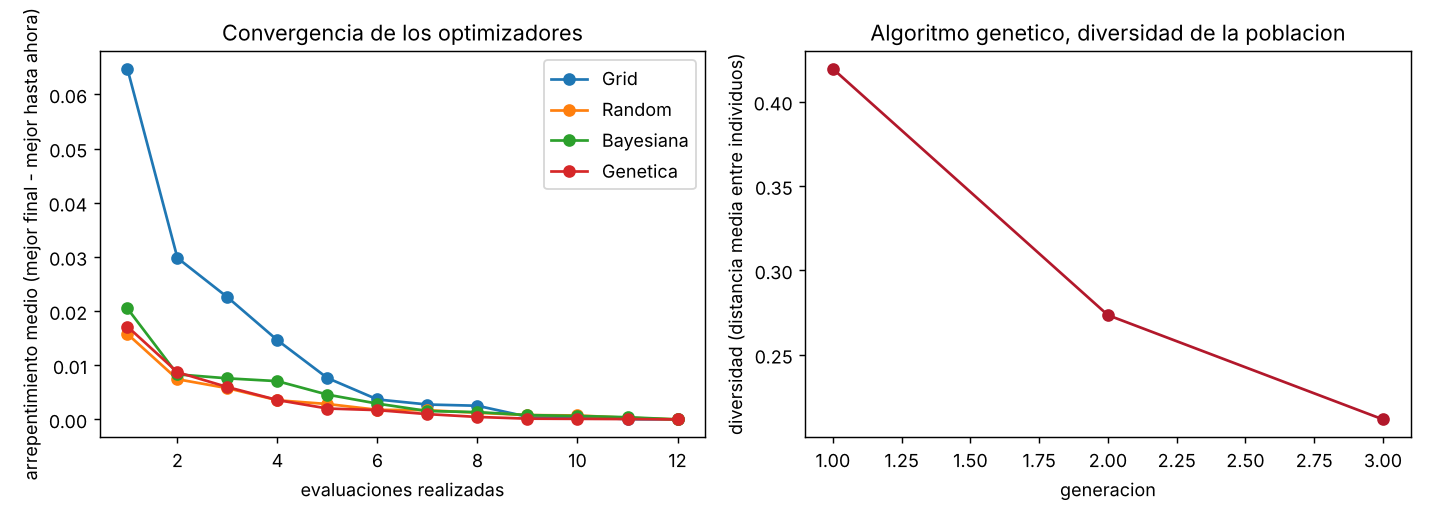

In [8]:
display(pd.read_csv(RES / "convergencia_resumen.csv").rename(columns={"evals":"evaluaciones","PR_AUC_interno":"PR-AUC interno","evals_hasta_cerca_del_optimo":"evaluaciones hasta llegar a 0.002 del óptimo","t_busqueda_s":"tiempo de búsqueda (s)","t_por_eval_s":"tiempo por evaluación (s)"}).style.hide(axis="index").format(precision=3))
display(Image(str(FIG / "convergencia.png")))

**Convergencia.** La curva de la izquierda muestra cuánto le falta a cada optimizador para llegar a su mejor valor final (el arrepentimiento) a medida que evalúa configuraciones. La Bayesiana y Random llegan a un valor muy cercano al óptimo en unas 4 evaluaciones, y la genética en unas 3, aunque con un óptimo final algo peor. La Bayesiana arranca con 4 evaluaciones aleatorias (arranque del TPE) y recién después usa el modelo sustituto. Con espacios de búsqueda tan chicos (uno a cinco hiperparámetros) y un modelo con techo tan parejo, la ventaja de la optimización inteligente sobre la aleatoria es pequeña. Sería más visible con espacios más grandes como los de XGBoost completo o una red neuronal.

La diversidad de la población genética (derecha) cae de generación en generación, que es el comportamiento esperado de la selección y el cruce. Con una población de solo 4 individuos la convergencia es muy rápida y la exploración limitada, lo que explica que sea el optimizador con menos configuraciones distintas.

modelo,exponente empírico del tiempo de ajuste (t ~ n^k)
DecisionTree,0.92
EBM,0.58
KNN (brute),0.53
KNN (kd_tree),1.10
LinearSVC,1.13
LogReg (lbfgs),0.99
LogReg (liblinear),0.98
LogReg (saga),0.98
NaiveBayes,0.81
RandomForest,0.70


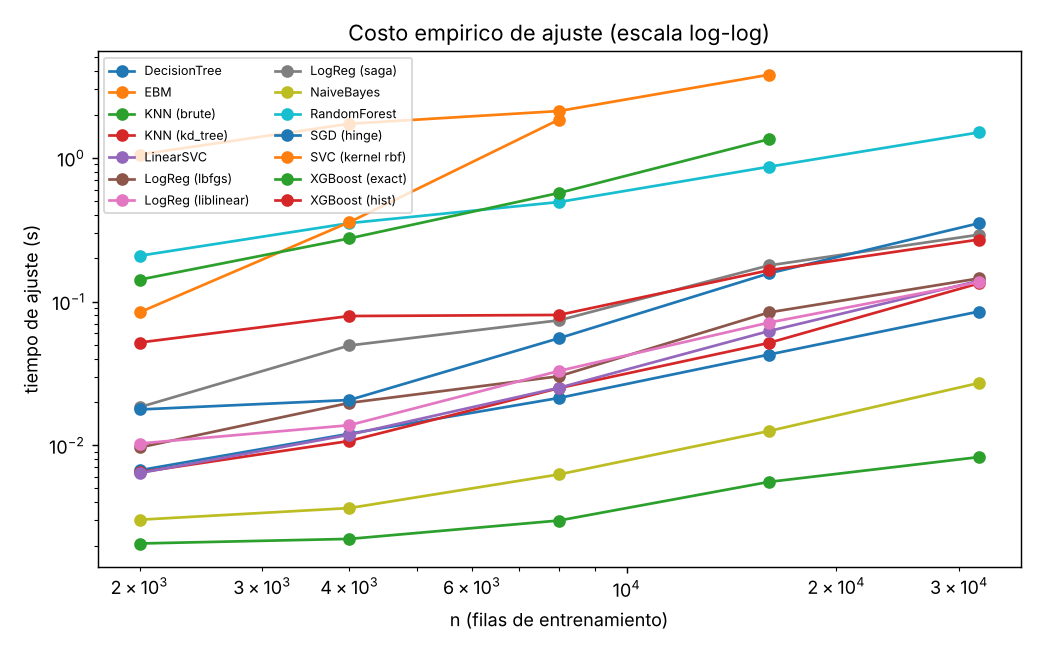

Tiempo de predicción para 2,000 consultas con KNN, según algoritmo de búsqueda.

modelo,KNN (brute),KNN (kd_tree)
n,,
2000,0.07,0.10
4000,0.07,0.20
8000,0.10,0.40
16000,0.17,0.82
32000,0.34,2.22


In [9]:
cx = pd.read_csv(RES / "complejidad_empirica.csv"); ex = pd.read_csv(RES / "complejidad_exponentes.csv")
display(ex.rename(columns={"exponente_empirico_fit":"exponente empírico del tiempo de ajuste (t ~ n^k)"}).style.hide(axis="index").format(precision=2))
display(Image(str(FIG / "complejidad.png")))
kn = cx[cx.modelo.str.startswith("KNN")].pivot(index="n", columns="modelo", values="t_pred_2000_s")
display(Markdown("Tiempo de predicción para 2,000 consultas con KNN, según algoritmo de búsqueda."))
display(kn.round(2))

Medimos el tiempo de ajuste con cantidades crecientes de filas (de 2,000 a 32,000) y estimamos el exponente de la ley de potencia entre tiempo y tamaño. Lo que encontramos, comparado con lo que dice la teoría.

* **Modelos lineales** (logística, SVM lineal, SGD). El exponente da cerca de 1, que es el crecimiento lineal en n que se espera para métodos que recorren los datos un número casi fijo de veces. A este tamaño y con 35 variables, SAGA (0.29 s con 32 mil filas) no fue más rápido que liblinear (0.14 s) ni que L-BFGS. SAGA gana cuando n y p son mucho más grandes, y a nuestra escala no hay ventaja.
* **SVM con kernel RBF.** Exponente de 2.2, cercano al n al cuadrado de la teoría. Con 8,000 filas ya tarda 1.9 s contra 0.03 s de la SVM lineal, y no lo extrapolamos a 45 mil. Por eso usamos la SVM lineal.
* **XGBoost.** El método de histogramas (`hist`) tiene un exponente de 0.58 contra 1.08 del método exacto, y con 16 mil filas es unas 8 veces más rápido (0.16 s contra 1.35 s). Es la razón de usar `hist` en todo el benchmark.
* **Random Forest.** Exponente de 0.70, por debajo de lo lineal porque el costo depende más de la profundidad y del número de árboles que de n.
* **KNN.** El ajuste es casi gratuito y todo el costo está en la predicción, que crece con n. La búsqueda por fuerza bruta (0.34 s para 2,000 consultas con 32 mil filas) resultó **más rápida** que el kd-tree (2.22 s). Con 35 dimensiones el kd-tree sufre la maldición de la dimensionalidad y casi no puede podar, algo que sí se esperaba en teoría, y que confirmamos medido.
* **EBM.** Exponente de 0.58, ajusta 16 mil filas en menos de 4 s, a pesar de ser un modelo con boosting cíclico por variable.

Otras decisiones de eficiencia fueron submuestrear la búsqueda interna, usar n_jobs de 1 por tarea y paralelizar entre tareas con 2 procesos, y guardar cada tarea en disco de forma que la corrida es reanudable. En total las 540 tareas sumaron unas 1.7 horas de cómputo de un solo núcleo (104 minutos sumando búsqueda y reajuste), repartidas así.

In [10]:
a = pd.read_csv(RES / "costo_total_por_modelo_min.csv"); b = pd.read_csv(RES / "costo_total_por_optimizador_min.csv")
display(pd.concat([a.rename(columns={a.columns[0]:"grupo", "t_total_s":"minutos"}), b.rename(columns={b.columns[0]:"grupo", "t_total_s":"minutos"})]).style.hide(axis="index"))

grupo,minutos
DecisionTree,6.400000
EBM,4.400000
KNN,16.600000
LogReg,11.600000
NaiveBayes,5.000000
RandomForest,29.300000
SVM,7.400000
XGBoost,23.800000
Bayesiana,32.600000
Genetica,17.400000


## 7. Evaluación final en el conjunto de prueba reservado

Elegimos como finalistas cuatro modelos sin balanceo, que fue lo mejor calibrado. Son la regresión logística, la SVM lineal, XGBoost y el EBM. Sus hiperparámetros salen de repetir la búsqueda bayesiana, pero esta vez sobre todo el entrenamiento (nunca sobre la prueba). Ajustamos con el entrenamiento completo y evaluamos en el conjunto de prueba. Los intervalos son bootstrap percentil con 1,000 remuestras.

Un detalle de transparencia. El script de evaluación final se ejecutó dos veces porque falló una línea de código después de calcular las métricas de prueba y hubo que corregirla. Los modelos y los hiperparámetros eran los mismos, las semillas están fijas, y no se tomó ninguna decisión mirando esos resultados, así que no hubo selección sobre la prueba.

In [11]:
display(pd.read_csv(RES / "test_final_metricas.csv").style.hide(axis="index"))
display(pd.read_csv(RES / "test_delong.csv").style.hide(axis="index").format(precision=4))
display(pd.read_json(RES / "hiperparametros_finales.json", typ="series").to_frame("hiperparámetros finales"))

modelo,PR_AUC,ROC_AUC,Brier,ECE
LogReg,0.538 [0.517-0.561],0.804 [0.794-0.814],0.128 [0.124-0.132],0.013 [0.009-0.021]
SVM,0.537 [0.515-0.560],0.803 [0.794-0.813],0.128 [0.124-0.132],0.018 [0.014-0.026]
XGBoost,0.541 [0.519-0.563],0.804 [0.795-0.814],0.128 [0.124-0.131],0.018 [0.015-0.026]
EBM,0.544 [0.522-0.566],0.804 [0.794-0.814],0.127 [0.123-0.131],0.010 [0.009-0.018]


A,B,dif_AUC,p,p_Holm
LogReg,SVM,0.0003,0.5666,1.0000
LogReg,XGBoost,-0.0005,0.5885,1.0000
LogReg,EBM,-0.0001,0.9333,1.0000
XGBoost,EBM,0.0005,0.6168,1.0000
SVM,EBM,-0.0004,0.6375,1.0000


,hiperparámetros finales
LogReg,"{'penalty': 'l2', 'C': 1.012919795684573}"
SVM,{'C': 0.031489116479568}
XGBoost,"{'n_estimators': 236, 'max_depth': 2, 'learnin..."
EBM,"{'learning_rate': 0.005448183222966, 'max_leav..."


Los cuatro modelos quedan prácticamente iguales, con ROC-AUC de 0.804, PR-AUC entre 0.537 y 0.544 y Brier de 0.127 a 0.128, y estos valores son consistentes con los del Entregable 2 (0.538 y 0.804). Los intervalos se solapan casi por completo y ninguna de las comparaciones de DeLong con Holm es significativa. El EBM tiene el mejor punto estimado en PR-AUC, Brier y ECE (0.010), con la misma ROC-AUC que los otros, pero la diferencia está dentro del ruido. Lo que podemos afirmar es que el EBM **iguala** a los mejores modelos, no que los supere.

## 8. Calibración

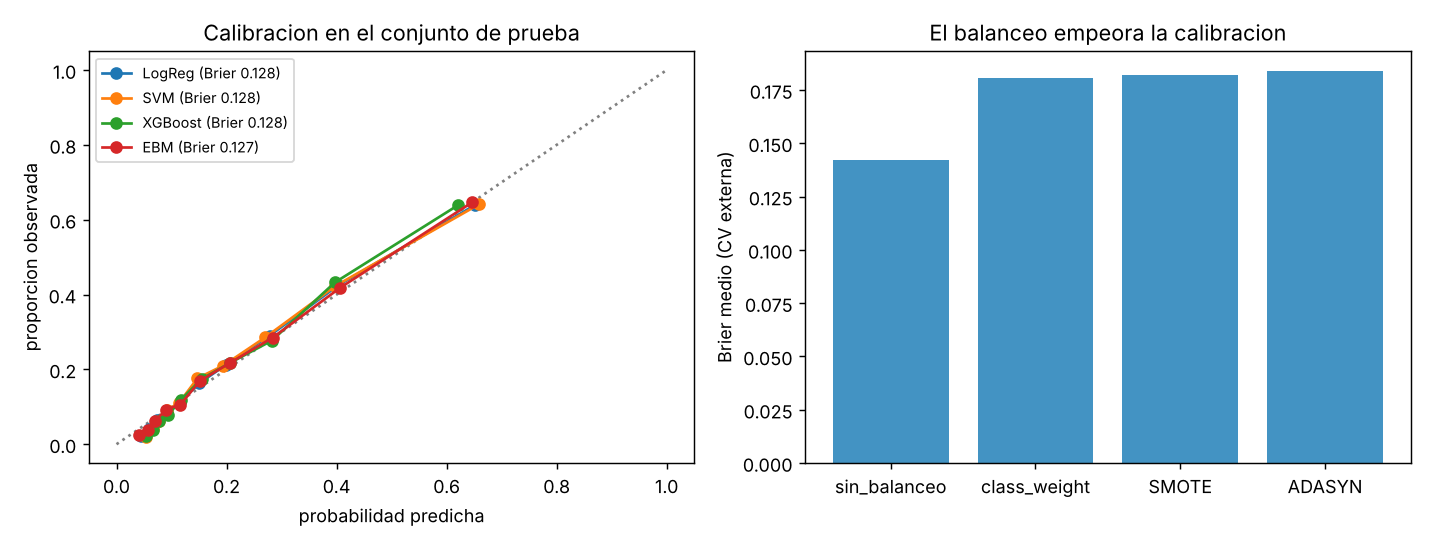

balanceo,ADASYN,SMOTE,class_weight,sin_balanceo
modelo,,,,
DecisionTree,0.162,0.158,0.218,0.015
KNN,0.199,0.188,NaN,0.059
LogReg,0.237,0.225,0.218,0.016
NaiveBayes,0.208,0.207,0.177,0.164
RandomForest,0.210,0.213,0.241,0.036
SVM,0.238,0.226,0.015,0.022
XGBoost,0.103,0.102,0.224,0.023


In [12]:
display(Image(str(FIG / "calibracion.png")))
display(pd.read_csv(RES / "calibracion_por_modelo_balanceo.csv").pivot_table(index="modelo", columns="balanceo", values="ECE").round(3))

A la izquierda están las curvas de calibración en la prueba, y los cuatro modelos sin balanceo siguen la diagonal muy de cerca. A la derecha está el Brier promedio por técnica de balanceo en la validación externa. La tabla de abajo muestra el error de calibración esperado (ECE) por modelo y balanceo, que en la logística pasa de 0.02 sin balanceo a más de 0.2 al balancear, salvo en la SVM, que como ya dijimos se recalibra con un ajuste sigmoide. Si el modelo se va a usar para tamizar y priorizar, conviene usar un umbral sobre un modelo sin balancear y calibrado, en lugar de balancear los datos.

## 9. Interpretabilidad (SHAP y EBM)

,SHAP_XGBoost,abs_coef_LogReg,EBM_importancia
frecuencia_depresion,0.512,4.576,0.426
depresion_dx,0.343,0.789,0.239
edad,0.305,2.451,0.231
dificultad_auditiva,0.278,1.841,0.255
dificultad_visual,0.255,1.642,0.230
educacion,0.167,1.559,0.166
colesterol_alto,0.092,0.244,0.096
tabaquismo,0.037,0.323,0.064
acv,0.037,0.522,0.035
imc_categoria,0.026,0.171,0.041


{'SHAP_vs_LogReg': 0.77, 'SHAP_vs_EBM': 0.96, 'LogReg_vs_EBM': 0.72}


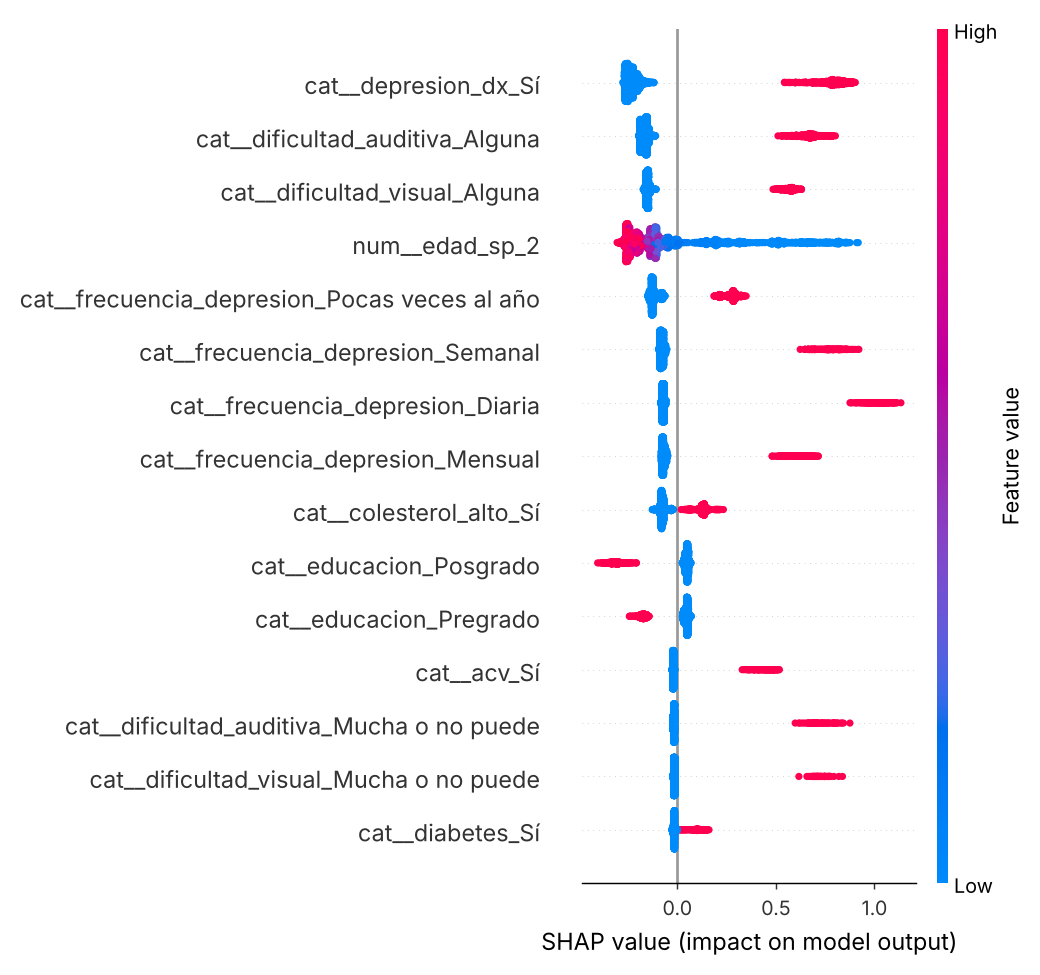

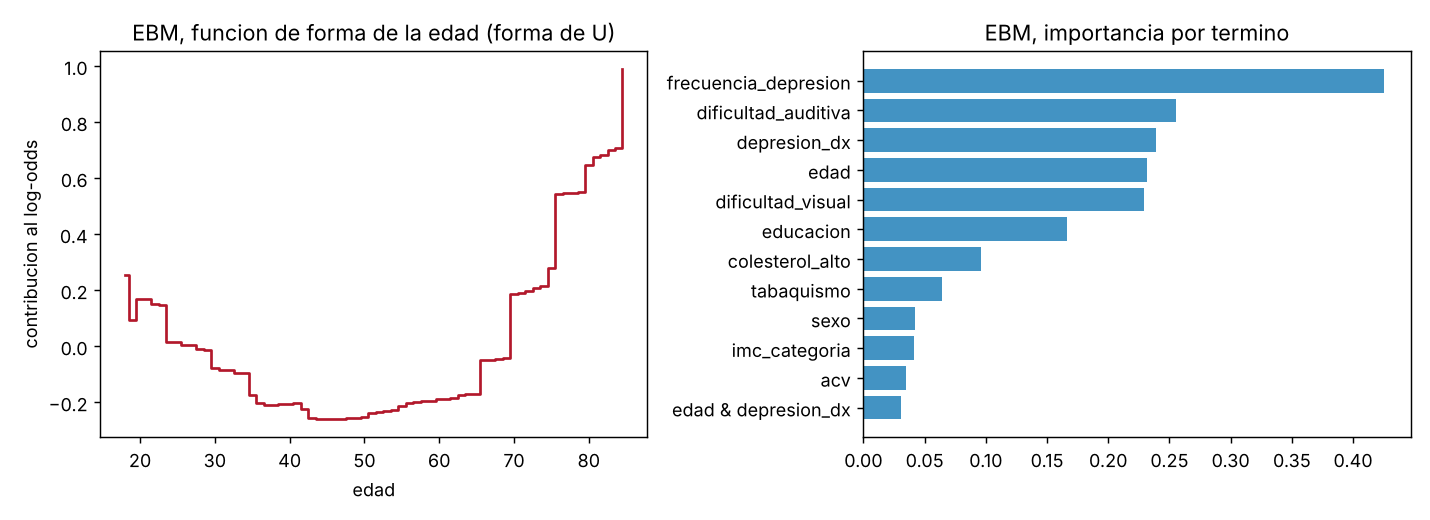

In [13]:
imp = pd.read_csv(RES / "importancia_variables.csv", index_col=0)
display(imp.head(12).round(3))
sp = json.load(open(RES / "acuerdo_importancias_spearman.json")); print({k: round(v, 2) for k, v in sp.items()})
display(Image(str(FIG / "shap_xgboost.png"))); display(Image(str(FIG / "ebm_global.png")))

Tres métodos distintos (SHAP sobre XGBoost, coeficientes de la logística y la importancia por término del EBM) coinciden en lo esencial. Las variables que más pesan son la frecuencia de síntomas depresivos, el diagnóstico de depresión, la edad, la dificultad auditiva, la dificultad visual y la educación. El acuerdo entre SHAP y el EBM es muy alto (correlación de Spearman de 0.96), y entre cada uno y la logística es de 0.72 a 0.77, algo menor porque la suma de valores absolutos de coeficientes sobre variables con varias categorías no es comparable de forma directa con las otras dos. La importancia de ACV es más baja de lo que uno esperaría por su peso clínico, algo que ya veíamos en el Entregable 2, donde el efecto del ACV aparecía sobre todo en las edades más jóvenes.

La función de forma de la edad en el EBM reproduce la U que habíamos visto en el EDA y que modelamos con splines en la logística, lo que sirve como validación cruzada de las dos formas de modelar la edad. SHAP explica un modelo ya entrenado desde afuera (aproximación basada en valores de Shapley), mientras que en el EBM la explicación **es** el modelo, sin aproximar nada. Esa es la ventaja práctica del EBM, que no pierde rendimiento y además se puede leer directamente.

### 9.1 LIME frente a SHAP en XGBoost

La guía pide comparar LIME con SHAP sobre XGBoost. Tomamos 150 adultos al azar del conjunto de prueba y calculamos para cada uno la explicación local con SHAP (exacto para árboles) y con LIME (3,000 perturbaciones por instancia). LIME entrega pendientes de un modelo lineal local en unidades estandarizadas, así que para compararlo con SHAP las convertimos en contribuciones multiplicando cada pendiente por el valor estandarizado de la instancia. Después sumamos las columnas derivadas (one-hot y splines) en su variable original.

medida,valor
Spearman global entre importancias SHAP y LIME,0.820000
Spearman local mediano (por instancia),0.790000
Rango intercuartil del Spearman local,"[0.63, 0.87]"
Coincidencia de las 3 variables principales,0.570000
"Estabilidad de LIME con otra semilla (Jaccard, top 5)",0.700000


,SHAP,LIME
frecuencia_depresion,0.502,0.008
depresion_dx,0.336,0.006
edad,0.294,0.026
dificultad_auditiva,0.283,0.004
dificultad_visual,0.246,0.006
educacion,0.167,0.003
colesterol_alto,0.092,0.003
tabaquismo,0.039,0.002


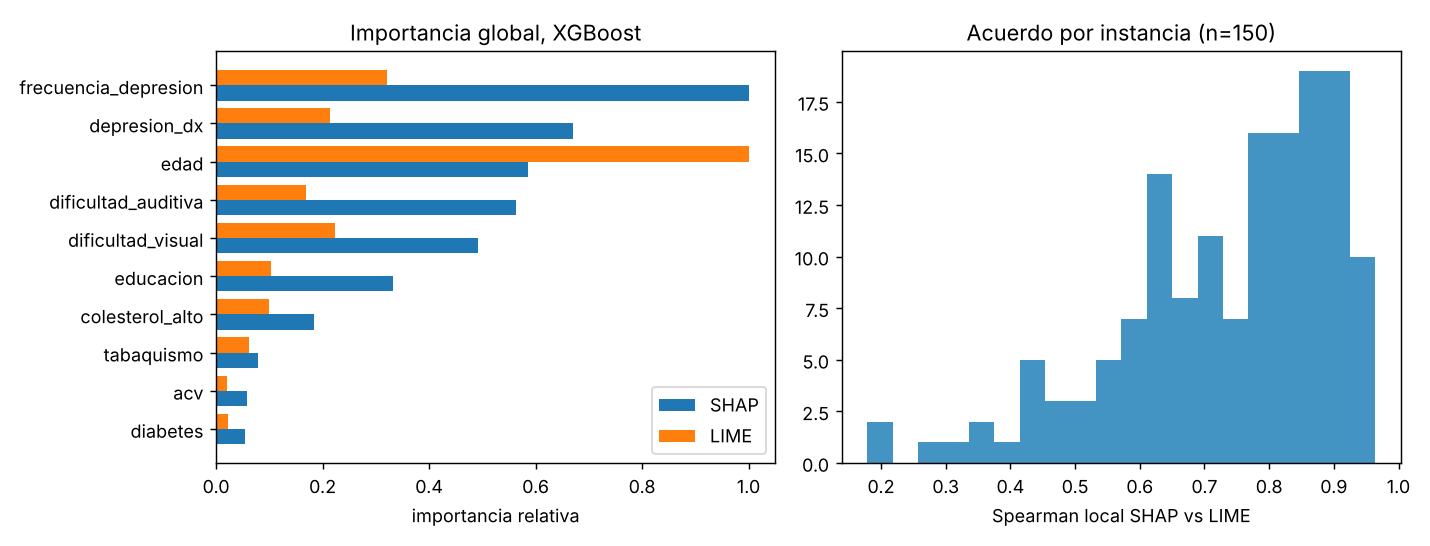

In [14]:
li = json.load(open(RES / "lime_vs_shap.json"))
display(pd.DataFrame({"medida": ["Spearman global entre importancias SHAP y LIME", "Spearman local mediano (por instancia)", "Rango intercuartil del Spearman local", "Coincidencia de las 3 variables principales", "Estabilidad de LIME con otra semilla (Jaccard, top 5)"],
  "valor": [round(li["spearman_global_SHAP_LIME"],2), round(li["spearman_local_mediana"],2), str([round(x,2) for x in li["spearman_local_rango_intercuartil"]]), round(li["coincidencia_top3_variables"],2), round(li["estabilidad_LIME_jaccard_top5"],2)]}).style.hide(axis="index"))
display(pd.read_csv(RES / "lime_vs_shap_global.csv", index_col=0).head(8).round(3))
display(Image(str(FIG / "lime_vs_shap.png")))

Los dos métodos coinciden en lo grueso. El orden global de variables es parecido (Spearman de 0.82) y por instancia el acuerdo es alto (mediana de 0.79), pero coinciden en las 3 variables principales solo en un 57 % de los casos. LIME también es menos estable, porque con otra semilla las 5 columnas principales se repiten en un 70 %. Hay una diferencia de fondo. SHAP reparte la predicción de forma exacta entre las variables con base en valores de Shapley, mientras que LIME ajusta un modelo lineal en una vecindad aleatoria, que depende del muestreo y del ancho de esa vecindad. En el orden global LIME le da más peso relativo a la edad que SHAP, algo esperable porque la edad entra al modelo como varias columnas spline altamente correlacionadas y LIME reparte su efecto de forma menos estable. Por eso preferimos SHAP para la interpretación y usamos LIME como contraste. Las magnitudes absolutas de LIME y de SHAP no son comparables (una es probabilidad y la otra log-odds), por eso comparamos solo órdenes.

## 10. Robustez y sensibilidad

Acá cerramos los análisis de sensibilidad que quedaron pendientes en el Entregable 2 (pesos muestrales, umbral de decisión y datos faltantes) y sumamos otros.

In [15]:
rob = pd.read_csv(RES / "robustez.csv")
for a in rob.analisis.unique():
    display(Markdown(f"**{a.replace('_',' ').capitalize()}**"))
    display(rob[rob.analisis == a].drop(columns="analisis").style.hide(axis="index").format(precision=3))

**Pesos muestrales en evaluacion**

modelo_o_grupo,metrica,valor
LogReg,PR_AUC sin pesos,0.5384440870218361
LogReg,PR_AUC con pesos,0.5316610836900492
LogReg,Brier sin pesos,0.127662697393982
LogReg,Brier con pesos,0.12053377370105893
SVM,PR_AUC sin pesos,0.5372796033127729
SVM,PR_AUC con pesos,0.5295714432398566
SVM,Brier sin pesos,0.12805462678755883
SVM,Brier con pesos,0.12096296264423065
XGBoost,PR_AUC sin pesos,0.5405852551883632
XGBoost,PR_AUC con pesos,0.5316804239380755


**Reajuste con pesos**

modelo_o_grupo,metrica,valor
LogReg,PR_AUC (eval. con pesos),0.5304335397420928
LogReg,Brier (eval. con pesos),0.12055320690980337


**Umbral logreg**

...

modelo_o_grupo,metrica,valor
LogReg,"ruido_leve (edad+-2, 5% cambiado) ROC_AUC",0.7918851018040284
SVM,"ruido_leve (edad+-2, 5% cambiado) ROC_AUC",0.7893741598158833
XGBoost,"ruido_leve (edad+-2, 5% cambiado) ROC_AUC",0.792790606064707
EBM,"ruido_leve (edad+-2, 5% cambiado) ROC_AUC",0.7919241253301458
LogReg,"ruido_fuerte (edad+-5, 15% cambiado) ROC_AUC",0.7624707572150231
SVM,"ruido_fuerte (edad+-5, 15% cambiado) ROC_AUC",0.7567919327514131
XGBoost,"ruido_fuerte (edad+-5, 15% cambiado) ROC_AUC",0.764366603706771
EBM,"ruido_fuerte (edad+-5, 15% cambiado) ROC_AUC",0.7630115810863035


**Subgrupos logreg**

modelo_o_grupo,metrica,valor
"edad=(17.0, 39.0] (n=3223)",ROC_AUC / Brier / prev. obs. / prev. pred.,0.807 / 0.109 / 0.164 / 0.172
"edad=(39.0, 59.0] (n=3365)",ROC_AUC / Brier / prev. obs. / prev. pred.,0.829 / 0.101 / 0.162 / 0.162
"edad=(59.0, 74.0] (n=3162)",ROC_AUC / Brier / prev. obs. / prev. pred.,0.762 / 0.144 / 0.221 / 0.226
"edad=(74.0, 90.0] (n=1455)",ROC_AUC / Brier / prev. obs. / prev. pred.,0.733 / 0.197 / 0.370 / 0.346
sexo=Hombre (n=5104),ROC_AUC / Brier / prev. obs. / prev. pred.,0.799 / 0.118 / 0.180 / 0.185
sexo=Mujer (n=6121),ROC_AUC / Brier / prev. obs. / prev. pred.,0.804 / 0.136 / 0.228 / 0.225
raza_etnia=Asiático no hispano (n=657),ROC_AUC / Brier / prev. obs. / prev. pred.,0.826 / 0.083 / 0.111 / 0.119
raza_etnia=Blanco no hispano (n=7375),ROC_AUC / Brier / prev. obs. / prev. pred.,0.798 / 0.136 / 0.223 / 0.223
raza_etnia=Hispano (n=1709),ROC_AUC / Brier / prev. obs. / prev. pred.,0.791 / 0.113 / 0.170 / 0.170
raza_etnia=Negro no hispano (n=1202),ROC_AUC / Brier / prev. obs. / prev. pred.,0.819 / 0.119 / 0.193 / 0.197


**Temporal 2022 a 2023**

modelo_o_grupo,metrica,valor
LogReg,PR_AUC / ROC_AUC,0.515 / 0.791
XGBoost,PR_AUC / ROC_AUC,0.516 / 0.789
EBM,PR_AUC / ROC_AUC,0.516 / 0.791


* **Pesos muestrales.** Al evaluar con los pesos de la encuesta, el Brier baja de 0.128 a 0.121 y la PR-AUC baja un poco, de 0.538 a 0.532. Reajustar la logística con pesos casi no cambia nada (PR-AUC ponderada de 0.530). Es decir que el ranking de modelos no depende de usar o no los pesos. Lo que los pesos corrigen son las estimaciones de prevalencia y no la varianza, así que **nuestros intervalos siguen ignorando el diseño muestral (estratos y unidades primarias de muestreo)**, y lo declaramos como limitación, tal como lo pidió el profesor.
* **Umbral.** Con el umbral que maximiza el F1 fuera de partición en el entrenamiento (0.245) la logística logra un F1 de 0.535, recall de 0.64 y precisión de 0.46 en la prueba. Subir el umbral gana precisión a costa de recall, y con 0.5 el recall cae a 0.31. El umbral debe fijarse según el uso, y no por defecto.
* **Datos faltantes.** En los 701 casos de la prueba con algún dato faltante, la ROC-AUC es de 0.800 en la logística contra 0.804 en los casos completos, es decir que la imputación con indicadores de faltante se comporta bien. El EBM baja más en ese subgrupo (0.793 contra 0.805), aunque con solo 701 casos esa diferencia es incierta.
* **Perturbación de las entradas.** Con ruido leve (edad con error de más o menos 2 años y 5 % de variables cambiadas al azar) la ROC-AUC baja unos 0.01 en todos los modelos. Con ruido fuerte (más o menos 5 años y 15 %) baja de 0.80 a unos 0.76. Los cuatro modelos se degradan de forma parecida, y ninguno es más frágil.
* **Subgrupos.** La discriminación es buena en jóvenes y adultos de mediana edad (ROC-AUC de 0.81 a 0.83) y baja en mayores de 74 (0.73), donde además el Brier sube a 0.197 y la prevalencia observada es más alta que la predicha (0.370 contra 0.346). Por sexo y por raza o etnia la ROC-AUC va de 0.79 a 0.83 con la excepción del grupo Otro o múltiple (n pequeño, 137), y la calibración en cada subgrupo es muy buena, así que no vemos una brecha de equidad llamativa. Esto debe leerse como descriptivo.
* **Validación temporal.** Entrenar con 2022 y evaluar con 2023 da PR-AUC de 0.515 y ROC-AUC de 0.79 para los tres modelos probados, un poco menos que la validación aleatoria, que es lo esperable al cambiar de año, sin signos de que el modelo dependa del año de la encuesta.

## 11. El modelo original (EBM) frente al resto

En la validación anidada, el EBM promedió PR-AUC de 0.520, ROC-AUC de 0.793, Brier de 0.131 y ECE de 0.016. Frente a la mejor combinación por PR-AUC (SVM sin balanceo) la diferencia de AUC es de menos 0.0002 (p de 0.66, Holm de 1), y frente a la mejor logística es de menos 0.0000 (p de 0.93). Frente al mejor XGBoost (class_weight con Bayesiana) la diferencia es de más 0.0015 y sí es significativa tras Holm (p ajustado de 0.016), pero ese XGBoost viene de una combinación que destruye la calibración (Brier de 0.183), así que es una comparación poco favorable para XGBoost y no una ventaja real del EBM.

In [16]:
display(pd.read_csv(RES / "ebm_vs_referencias.csv").style.hide(axis="index").format(precision=4))

referencia,combo,dif_AUC_EBM_menos_ref,p,cliffs_delta_PR_AUC,p_Holm
mejor_PR_AUC,SVM|sin_balanceo|Grid,-0.0002,0.6609,-0.0400,1.0000
mejor_LogReg,LogReg|sin_balanceo|Random,-0.0000,0.9253,0.1200,1.0000
mejor_XGBoost,XGBoost|class_weight|Bayesiana,0.0015,0.0053,-0.0400,0.0159


Nuestra lectura es honesta. El EBM no mejora el desempeño predictivo, que está en el techo de la información disponible, pero tampoco lo empeora, y a cambio entrega un modelo interpretable de forma nativa (una curva por variable y sus interacciones), bien calibrado y de ajuste rápido. Para un modelo pensado para uso clínico y de salud pública con datos de encuesta, esa combinación es el argumento a su favor.

## 12. Correcciones a la entrega anterior

Estas son las observaciones del profesor sobre la entrega anterior y lo que hicimos con cada una.

* **Numeración de secciones.** Las secciones de este notebook van numeradas de 1 a 14. La numeración interna de los notebooks 01 a 04 (que mezcla la numeración de la guía, como 2.5 o 2.9) queda pendiente de revisar a mano, porque está atada a la numeración de la guía del profesor.
* **Lista de referencias.** Se actualizó `referencias.md` con las referencias nuevas de este entregable.
* **Conteo de variables en la auditoría de fuga.** Son 11 predictoras restantes y no 10 (14 predictoras menos las 3 en observación). Corregido en los notebooks 00 y 03.
* **Intervalos que ignoran el diseño muestral.** Declarado de forma explícita en la sección 10 y en las limitaciones.
* **Análisis de sensibilidad pendiente.** Hecho en la sección 10 (pesos muestrales, umbral, faltantes, perturbaciones, subgrupos y validación temporal).

## 13. Reproducibilidad e ingeniería del pipeline

* **Entorno fijado.** `requirements.txt` fija las versiones de los notebooks 01 a 04 y `requirements-entregable3.txt` fija las del benchmark, con Python 3.13. LIME se instala con pip, y si falla la compilación se puede usar el sdist como describe el archivo.
* **Semilla.** Una semilla global (`SEED = 42` en `src/utils.py`) que se propaga a la partición, a scikit-learn, a XGBoost, a Optuna, a imblearn y al algoritmo genético (DEAP). La búsqueda de cada fold externo usa 42 más el índice del fold.
* **Registro estructurado.** Cada tarea guarda un JSON con sus métricas, sus hiperparámetros finales, el historial completo de la búsqueda interna, los tiempos y un archivo con las predicciones fuera de fold. La tabla maestra (`resultados/tabla_maestra.csv`) resume las 108 combinaciones con las métricas del bucle externo, los hiperparámetros finales por fold, el tiempo de ejecución y la semilla.
* **Modularidad.** Carga y preprocesamiento en `src/utils.py` y `src/preprocesamiento.py`, modelos, optimizadores y evaluación en `src/benchmark.py`, pruebas estadísticas en `src/estadistica.py`, y scripts de ejecución en `scripts/`.
* **Cómo reproducir.** `python scripts/run_benchmark.py` (reanudable), luego `scripts/run_ebm.py`, `scripts/analisis.py`, `scripts/finales.py`, `scripts/complejidad.py` y `scripts/lime_vs_shap.py`, y por último este notebook.

## 14. Limitaciones y conclusiones

**Limitaciones.**
* La búsqueda de hiperparámetros se hizo sobre submuestras de 8,000 filas con un presupuesto de unas 12 evaluaciones, y es posible que con más recursos algún modelo (sobre todo XGBoost) ganara algo.
* La genética tuvo un presupuesto efectivo menor que los demás (6.9 contra 12 evaluaciones), así que su comparación con el resto no es del todo justa.
* Con 5 folds externos el Friedman global y el Nemenyi tienen poca potencia, y los resultados por factor promedian combinaciones que no son independientes.
* Los intervalos y los errores estándar no incorporan el diseño muestral de la NHIS. Los datos son transversales y autorreportados.
* SMOTE y ADASYN se aplicaron sobre variables ya transformadas, no con SMOTE-NC.
* La brecha de literatura sobre el EBM es una observación sobre las listas que revisamos y no una prueba de que no exista trabajo previo.
* Las 28 combinaciones de regresión no se hicieron porque no aplican al desenlace binario.

**Conclusiones.**
1. Con 14 predictoras de factores de riesgo modificables, el rendimiento se estanca en una PR-AUC cercana a 0.54 y una ROC-AUC de 0.80 en la prueba, sin importar el modelo, el balanceo o el optimizador, siempre que el modelo tenga capacidad mínima.
2. La complejidad extra no compra rendimiento. La logística, la SVM lineal, XGBoost y el EBM son estadísticamente indistinguibles, y por eso conviene elegir por interpretabilidad y costo.
3. El balanceo con remuestreo o pesos de clase no mejora la discriminación y daña la calibración, así que es preferible no balancear y mover el umbral.
4. Los métodos de optimización inteligentes (Bayesiano) dan una ventaja pequeña con espacios de búsqueda tan chicos, y su costo de cómputo es mayor que el de Random.
5. El EBM, modelo original del entregable, iguala al mejor modelo y es interpretable de forma nativa, con las mismas variables clave que SHAP y la logística.